# Customer segmentation — explore, clean and cluster
Customers differ in income, age and spending patterns. I first explore the data and record cleaning decisions, then compare K-Means and Ward hierarchical clustering.

The original analysis compared income with spending, age with spending, and all three numeric features. Those views remain. Gender is used for descriptive exploration; it is not part of the clustering distance. CustomerID is an identifier, not a predictor.

Run the cells in order. The source CSV stays unchanged; `raw_data` preserves its contents and `dataset` contains the cleaned values used below. Cluster labels describe this sample and need business interpretation before any customer-facing decision.


## 1. Setup and load the source data


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as shc

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
N_INIT = 20
ID_COLUMN = "CustomerID"
NUMERIC_COLUMNS = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
REQUIRED_COLUMNS = [ID_COLUMN, "Gender", *NUMERIC_COLUMNS]

# Start Jupyter from clustering/ or the repository root; no absolute path needed.
DATA_PATH = next(
    (candidate for location in (Path.cwd(), *Path.cwd().parents)
     for candidate in (location / "mall_customers.csv", location / "clustering" / "mall_customers.csv")
     if candidate.is_file()), None,
)
if DATA_PATH is None:
    raise FileNotFoundError("Open Jupyter from the repository root or clustering folder.")
raw_data = pd.read_csv(DATA_PATH)
missing_columns = set(REQUIRED_COLUMNS) - set(raw_data.columns)
if missing_columns:
    raise ValueError(f"Missing required source columns: {sorted(missing_columns)}")
print("Source:", DATA_PATH.name)
print("Rows and columns:", raw_data.shape)
display(raw_data.head(10))


Matplotlib is building the font cache; this may take a moment.


Source: mall_customers.csv
Rows and columns: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## 2. Understand the columns and sample
Annual income is recorded in thousands of dollars; Spending Score is a 1–100 score, not a dollar amount. Age is measured in years. I inspect schema, ranges and category sizes before treating any feature as a clustering input.


In [2]:
roles = {
    "CustomerID": "Identifier; excluded from clustering",
    "Gender": "Descriptive category; excluded from clustering",
    "Age": "Customer age in years",
    "Annual Income (k$)": "Annual income in thousands of dollars",
    "Spending Score (1-100)": "Spending score on a 1–100 scale",
}
schema = pd.DataFrame({
    "dtype": raw_data.dtypes.astype(str),
    "non_null": raw_data.notna().sum(),
    "unique_values": raw_data.nunique(dropna=True),
    "role": pd.Series(roles),
})
display(schema)
display(raw_data.describe(include="all").T)

# A separate exploration copy makes malformed numeric values visible as gaps.
eda = raw_data[REQUIRED_COLUMNS].copy()
for column in [ID_COLUMN, *NUMERIC_COLUMNS]:
    eda[column] = pd.to_numeric(eda[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
eda[NUMERIC_COLUMNS] = eda[NUMERIC_COLUMNS].astype(float)


,dtype,non_null,unique_values,role
CustomerID,int64,200,200,Identifier; excluded from clustering
Gender,str,200,2,Descriptive category; excluded from clustering
Age,int64,200,51,Customer age in years
Annual Income (k$),int64,200,64,Annual income in thousands of dollars
Spending Score (1-100),int64,200,84,Spending score on a 1–100 scale


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


## 3. Data-quality audit before cleaning
Check missingness, numeric parsing, duplicate records, repeated IDs and plausible values. Repeated numeric profiles with different IDs can represent different customers and are retained. Conflicting records with the same ID require review rather than arbitrary averaging.

Domain rules: IDs must be positive integers, age must be positive, income cannot be negative, and spending score must lie in [1, 100]. High income or a low spending score alone is not a data error.


In [3]:
missingness = pd.DataFrame({
    "missing_count": raw_data.isna().sum(),
    "missing_percent": raw_data.isna().mean().mul(100),
})
display(missingness)
parsing_issues = pd.Series({
    column: int((raw_data[column].notna() & eda[column].isna()).sum())
    for column in [ID_COLUMN, *NUMERIC_COLUMNS]
}, name="non_numeric_or_nonfinite_count")
display(parsing_issues.to_frame())
id_valid = eda[ID_COLUMN].notna() & (eda[ID_COLUMN] > 0) & (eda[ID_COLUMN] % 1 == 0)
invalid_values = pd.DataFrame({
    "invalid_id": ~id_valid,
    "invalid_age": eda.Age.notna() & (eda.Age <= 0),
    "invalid_income": eda["Annual Income (k$)"].notna() & (eda["Annual Income (k$)"] < 0),
    "invalid_spending_score": eda["Spending Score (1-100)"].notna() & ~eda["Spending Score (1-100)"].between(1, 100),
})
display(invalid_values.sum().to_frame("invalid_count"))
duplicate_audit = pd.Series({
    "exact_duplicate_records": int(raw_data[REQUIRED_COLUMNS].duplicated().sum()),
    "repeated_nonmissing_ids": int(eda.loc[id_valid, ID_COLUMN].duplicated().sum()),
    "repeated_numeric_profiles": int(eda[NUMERIC_COLUMNS].duplicated().sum()),
}, name="duplicate_audit")
display(duplicate_audit.to_frame())
if invalid_values.any(axis=1).any():
    display(raw_data.loc[invalid_values.any(axis=1)])
if raw_data[ID_COLUMN].duplicated(keep=False).any():
    display(raw_data.loc[raw_data[ID_COLUMN].duplicated(keep=False)].sort_values(ID_COLUMN))


,missing_count,missing_percent
CustomerID,0,0.0
Gender,0,0.0
Age,0,0.0
Annual Income (k$),0,0.0
Spending Score (1-100),0,0.0


,non_numeric_or_nonfinite_count
CustomerID,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


,invalid_count
invalid_id,0
invalid_age,0
invalid_income,0
invalid_spending_score,0


,duplicate_audit
exact_duplicate_records,0
repeated_nonmissing_ids,0
repeated_numeric_profiles,0


## 4. Numeric distributions, scales and outliers
Histograms show concentration and tails; boxplots highlight unusual values. Distance-based methods are affected by feature spread, so I inspect standard deviation and range as well as the median. IQR flags support review and do not automatically remove customers.


,count,mean,std,min,25%,50%,75%,max,missing_count,skewness,iqr
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.0,70.0,0,0.485569,20.25
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0,0,0.321843,36.50
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0,0,-0.047220,38.25


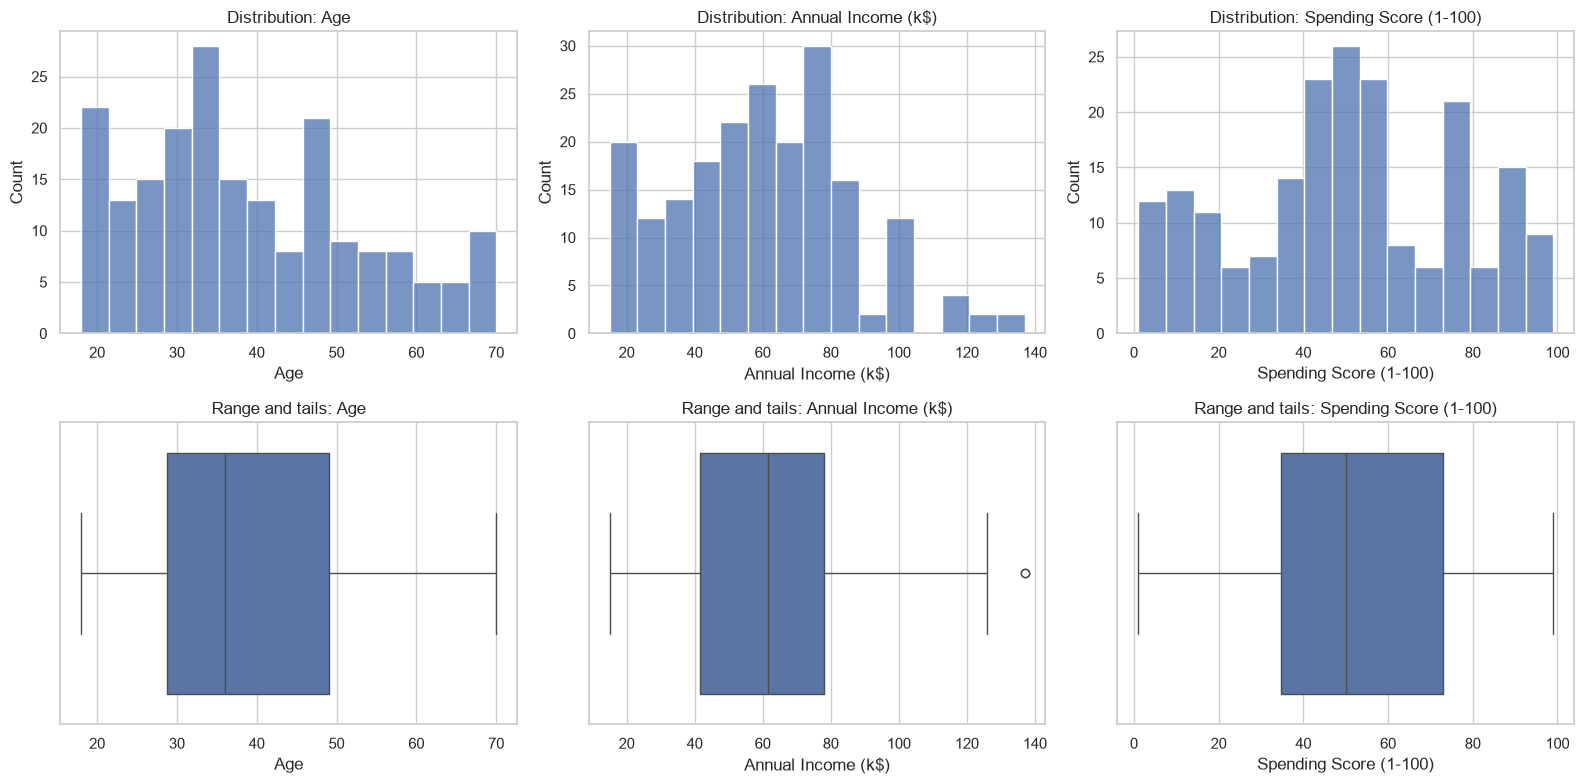

,iqr_review_flags
Age,0
Annual Income (k$),2
Spending Score (1-100),0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [4]:
numeric_summary = eda[NUMERIC_COLUMNS].describe().T
numeric_summary["missing_count"] = eda[NUMERIC_COLUMNS].isna().sum()
numeric_summary["skewness"] = eda[NUMERIC_COLUMNS].skew()
numeric_summary["iqr"] = eda[NUMERIC_COLUMNS].quantile(.75) - eda[NUMERIC_COLUMNS].quantile(.25)
display(numeric_summary)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, column in enumerate(NUMERIC_COLUMNS):
    sns.histplot(data=eda, x=column, bins=15, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution: {column}")
    sns.boxplot(data=eda, x=column, ax=axes[1, i])
    axes[1, i].set_title(f"Range and tails: {column}")
plt.tight_layout()
plt.show()

q1, q3 = eda[NUMERIC_COLUMNS].quantile(.25), eda[NUMERIC_COLUMNS].quantile(.75)
iqr = q3 - q1
outlier_flags = (eda[NUMERIC_COLUMNS] < q1 - 1.5 * iqr) | (eda[NUMERIC_COLUMNS] > q3 + 1.5 * iqr)
display(outlier_flags.sum().to_frame("iqr_review_flags"))
display(raw_data.loc[outlier_flags.any(axis=1), REQUIRED_COLUMNS])


## 5. Relationships and possible segmentation features
Compare income/spending, age/spending and age/income. Correlation summarizes a global linear pattern and can hide separate groups; scatterplots help inspect those groups. A spending score is not a prediction target here.


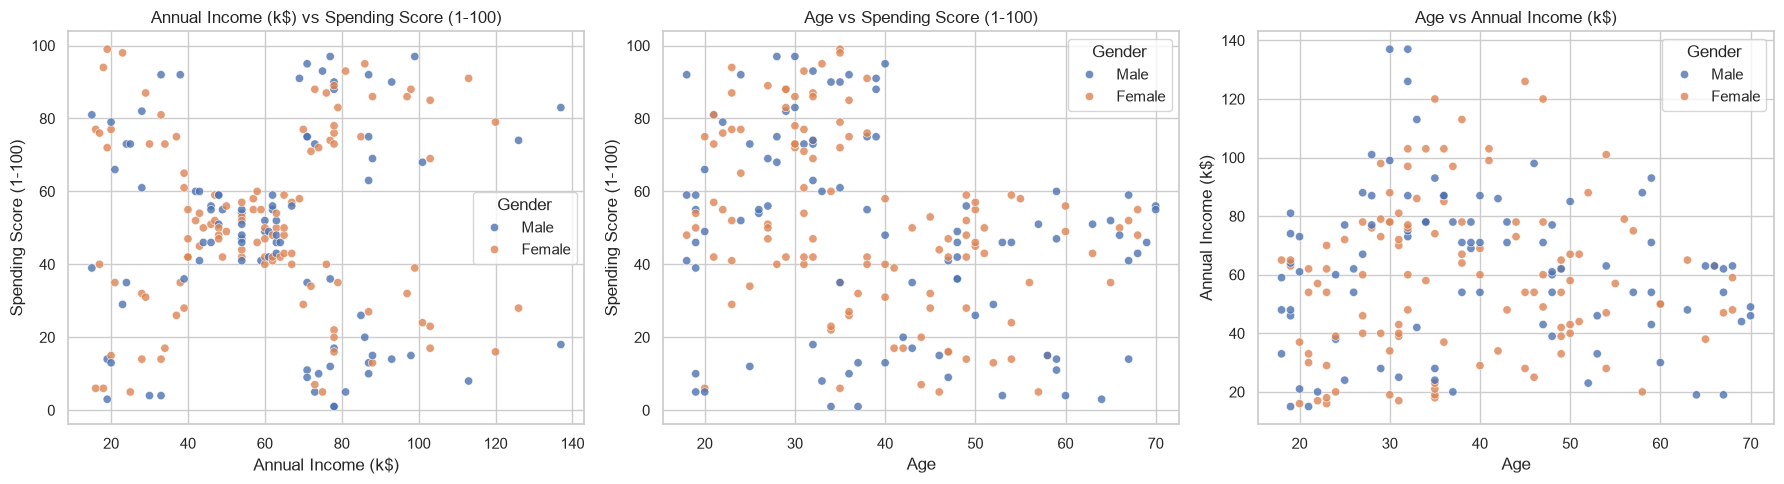

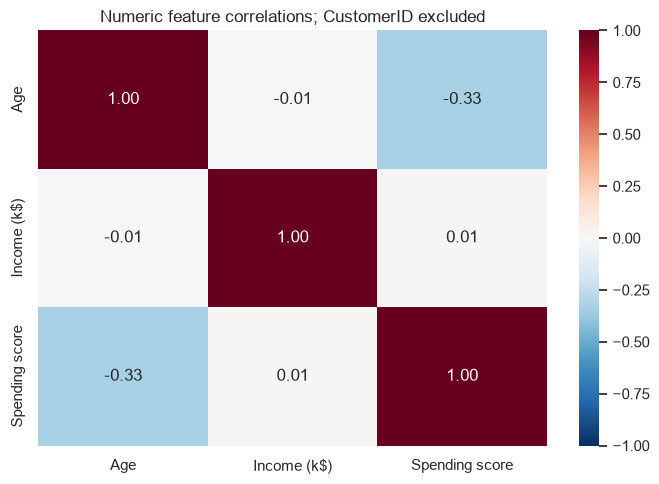

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, [
    ("Annual Income (k$)", "Spending Score (1-100)"),
    ("Age", "Spending Score (1-100)"),
    ("Age", "Annual Income (k$)"),
]):
    sns.scatterplot(data=eda, x=x, y=y, hue="Gender", alpha=.8, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(eda[NUMERIC_COLUMNS].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r",
            xticklabels=["Age", "Income (k$)", "Spending score"],
            yticklabels=["Age", "Income (k$)", "Spending score"], ax=ax)
ax.set_title("Numeric feature correlations; CustomerID excluded")
plt.tight_layout()
plt.show()


## 6. Descriptive age and gender comparisons
The original notebook investigated customers under 40 and spending scores above 40. I preserve those thresholds as editable descriptive views. Counts and within-group percentages must be considered together; a small sample difference does not establish a population-level or causal spending preference.


,customers,median_age,median_income,median_spending,scored_customers,score_above_threshold,above_threshold_percent
Gender,,,,,,,
Female,112,35.0,60.0,50.0,112,78,69.642857
Male,88,37.0,62.5,50.0,88,59,67.045455


,customers,median_age,median_income,median_spending,scored_customers,score_above_threshold,above_threshold_percent
age_band,,,,,,,
Under 30,55,23.0,57.0,56.0,55,46,83.636364
30–39,61,34.0,76.0,72.0,61,45,73.770492
40–49,39,46.0,61.0,36.0,39,17,43.589744
50+,45,59.0,54.0,46.0,45,29,64.444444


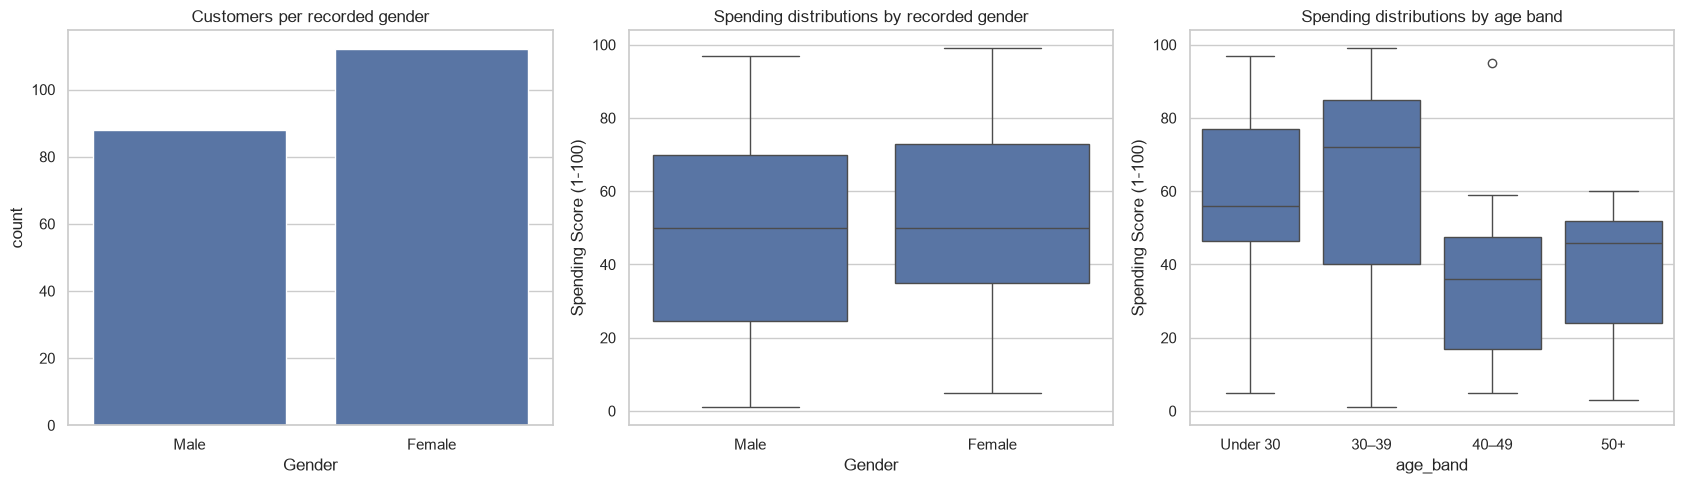

In [6]:
SPENDING_THRESHOLD = 40
profile_data = eda.copy()
profile_data["Gender"] = profile_data["Gender"].astype("string").str.strip().str.title().fillna("Unknown")
profile_data["age_band"] = pd.cut(profile_data.Age, bins=[0, 30, 40, 50, np.inf],
                                  labels=["Under 30", "30–39", "40–49", "50+"], right=False)

def describe_groups(frame, group):
    summary = frame.groupby(group, observed=True, dropna=False).agg(
        customers=(ID_COLUMN, "size"),
        median_age=("Age", "median"),
        median_income=("Annual Income (k$)", "median"),
        median_spending=("Spending Score (1-100)", "median"),
        scored_customers=("Spending Score (1-100)", "count"),
        score_above_threshold=("Spending Score (1-100)", lambda values: (values > SPENDING_THRESHOLD).sum()),
    )
    summary["above_threshold_percent"] = 100 * summary.score_above_threshold / summary.scored_customers.replace(0, np.nan)
    return summary

display(describe_groups(profile_data, "Gender"))
display(describe_groups(profile_data, "age_band"))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.countplot(data=profile_data, x="Gender", ax=axes[0])
sns.boxplot(data=profile_data, x="Gender", y="Spending Score (1-100)", ax=axes[1])
sns.boxplot(data=profile_data, x="age_band", y="Spending Score (1-100)", ax=axes[2])
axes[0].set_title("Customers per recorded gender")
axes[1].set_title("Spending distributions by recorded gender")
axes[2].set_title("Spending distributions by age band")
plt.tight_layout()
plt.show()


## 7. Cleaning decisions
1. Preserve the source and numeric units; strip categorical whitespace and normalize the display of Gender.
2. Quarantine records without a valid positive integer customer ID. Drop only exact repeated customer records; stop for conflicting records sharing an ID.
3. Convert invalid numeric measurements to missing values. Quarantine rows with all three numeric features missing.
4. Fill remaining numeric gaps with the median, fitted on the retained exploratory sample. Gender gaps become Unknown; they do not affect numeric clustering.
5. Keep valid extremes and customers sharing a numeric profile. IQR flags are for inspection only.
6. Standardize numeric features separately for each feature view. Never include CustomerID or Gender in the distance matrix.

Median imputation can create artificial similarities. If future data contains substantial missingness, compare a complete-case or alternative-imputation analysis before interpreting clusters. This is exploratory clustering of the observed sample, so preprocessing is fitted to that sample; new-customer assignment would reuse the fitted imputer/scaler rather than refitting them.


In [7]:
def clean_customer_data(source):
    """Return cleaned customers, a transparent audit and quarantined records."""
    data = source[REQUIRED_COLUMNS].copy()
    original_rows = len(data)
    for column in [ID_COLUMN, *NUMERIC_COLUMNS]:
        data[column] = pd.to_numeric(data[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
    data[NUMERIC_COLUMNS] = data[NUMERIC_COLUMNS].astype(float)
    data["Gender"] = data["Gender"].astype("string").str.strip().str.title().replace("", pd.NA).fillna("Unknown")

    valid_id = data[ID_COLUMN].notna() & (data[ID_COLUMN] > 0) & (data[ID_COLUMN] % 1 == 0)
    rejected_ids = data.loc[~valid_id].copy()
    rejected_ids["reason"] = "Invalid or missing customer ID"
    data = data.loc[valid_id].copy()
    exact_duplicates = int(data.duplicated(subset=REQUIRED_COLUMNS).sum())
    data = data.drop_duplicates(subset=REQUIRED_COLUMNS, keep="first")
    conflicts = data.loc[data[ID_COLUMN].duplicated(keep=False)]
    if not conflicts.empty:
        display(conflicts.sort_values(ID_COLUMN))
        raise ValueError("Conflicting records share CustomerID; review them before clustering.")

    invalid = {
        "Age": data.Age.notna() & (data.Age <= 0),
        "Annual Income (k$)": data["Annual Income (k$)"].notna() & (data["Annual Income (k$)"] < 0),
        "Spending Score (1-100)": data["Spending Score (1-100)"].notna() & ~data["Spending Score (1-100)"].between(1, 100),
    }
    invalid_counts = {column: int(mask.sum()) for column, mask in invalid.items()}
    for column, mask in invalid.items():
        data.loc[mask, column] = np.nan
    no_features = data[NUMERIC_COLUMNS].isna().all(axis=1)
    rejected_features = data.loc[no_features].copy()
    rejected_features["reason"] = "All numeric clustering features missing"
    data = data.loc[~no_features].copy()
    if data.empty:
        raise ValueError("No usable customers remain after cleaning")
    all_missing = data[NUMERIC_COLUMNS].columns[data[NUMERIC_COLUMNS].isna().all()].tolist()
    if all_missing:
        raise ValueError(f"Cannot median-impute entirely missing features: {all_missing}")
    imputed_counts = data[NUMERIC_COLUMNS].isna().sum()
    imputer = SimpleImputer(strategy="median")
    data[NUMERIC_COLUMNS] = imputer.fit_transform(data[NUMERIC_COLUMNS])
    data[ID_COLUMN] = data[ID_COLUMN].astype(int)
    data = data.reset_index(drop=True)
    rejected = pd.concat([rejected_ids, rejected_features], ignore_index=True)
    audit = pd.DataFrame({
        "step": ["Source rows", "Invalid ID rows quarantined", "Exact duplicate records removed",
                 "Rows without numeric features quarantined", "Cleaned rows retained"],
        "rows": [original_rows, len(rejected_ids), exact_duplicates, len(rejected_features), len(data)],
    })
    repairs = pd.DataFrame({"invalid_values_set_missing": pd.Series(invalid_counts),
                            "values_imputed": imputed_counts,
                            "fitted_median": pd.Series(imputer.statistics_, index=NUMERIC_COLUMNS)})
    return data, audit, repairs, rejected, imputer

dataset, cleaning_audit, cleaning_repairs, rejected_rows, numeric_imputer = clean_customer_data(raw_data)
display(cleaning_audit)
display(cleaning_repairs)
display(dataset.head())
if not rejected_rows.empty:
    display(rejected_rows)


,step,rows
0,Source rows,200
1,Invalid ID rows quarantined,0
2,Exact duplicate records removed,0
3,Rows without numeric features quarantined,0
4,Cleaned rows retained,200


,invalid_values_set_missing,values_imputed,fitted_median
Age,0,0,36.0
Annual Income (k$),0,0,61.5
Spending Score (1-100),0,0,50.0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19.0,15.0,39.0
1,2,Male,21.0,15.0,81.0
2,3,Female,20.0,16.0,6.0
3,4,Female,23.0,16.0,77.0
4,5,Female,31.0,17.0,40.0


## 8. Verify the cleaned sample and prepare distances
The cleaning audit shows whether any records or values changed. Standardization gives each selected numeric feature comparable initial weight; it does not establish that the features are equally useful. Plots and segment profiles below use original units for interpretation.


In [8]:
assert dataset[ID_COLUMN].is_unique
assert dataset[ID_COLUMN].gt(0).all()
assert np.isfinite(dataset[NUMERIC_COLUMNS].to_numpy()).all()
assert dataset.Age.gt(0).all()
assert dataset["Annual Income (k$)"].ge(0).all()
assert dataset["Spending Score (1-100)"].between(1, 100).all()
if len(dataset) < 11:
    raise ValueError("Need at least 11 cleaned customers for the cluster-count diagnostics below")

income_features = ["Annual Income (k$)", "Spending Score (1-100)"]
age_features = ["Age", "Spending Score (1-100)"]
all_features = NUMERIC_COLUMNS.copy()
income_scaler, age_scaler, all_scaler = StandardScaler(), StandardScaler(), StandardScaler()
X = income_scaler.fit_transform(dataset[income_features])
Z = age_scaler.fit_transform(dataset[age_features])
transposed_df = all_scaler.fit_transform(dataset[all_features])
assert ID_COLUMN not in all_features and "Gender" not in all_features
display(pd.DataFrame({
    "original_std": dataset[all_features].std(ddof=0),
    "scaled_mean": transposed_df.mean(axis=0),
    "scaled_std": transposed_df.std(axis=0),
}, index=all_features))
print("Cleaned customers:", len(dataset))
print("Distance matrices (income/spending, age/spending, all numeric):", X.shape, Z.shape, transposed_df.shape)


,original_std,scaled_mean,scaled_std
Age,13.934041,-1.021405e-16,1.0
Annual Income (k$),26.198977,-2.131628e-16,1.0
Spending Score (1-100),25.758882,-1.465494e-16,1.0


Cleaned customers: 200
Distance matrices (income/spending, age/spending, all numeric): (200, 2) (200, 2) (200, 3)


**My exploration and cleaning conclusions:** record the strongest relationships, missingness/duplicate checks, unusual but valid customers, and any limitations of imputation or equal feature weighting before proceeding.


## 9. K-Means: income and spending
I inspect the elbow, silhouette (higher is better) and Davies–Bouldin (lower is better) before reviewing a five-cluster view, as in the original notebook. These scores describe geometry rather than business usefulness. Compare scores within the same feature view and scaling; WCSS is not comparable across different feature sets.


,k,wcss,silhouette,davies_bouldin
0,1,400.000000,NaN,NaN
1,2,269.691012,0.321271,1.266954
2,3,157.704008,0.466585,0.716482
3,4,108.921317,0.493907,0.709556
4,5,65.568408,0.554657,0.572236
5,6,55.057348,0.539880,0.654567
6,7,44.864756,0.528149,0.714784
7,8,37.148117,0.456721,0.757911
8,9,32.392268,0.457085,0.763226
9,10,29.685788,0.436212,0.764524


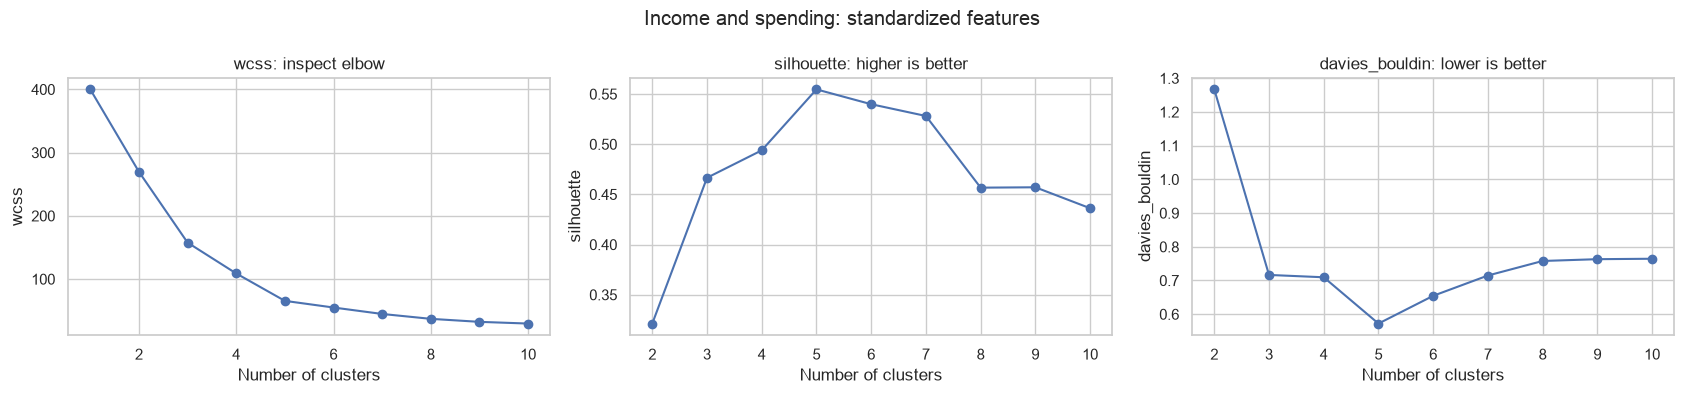

In [9]:
def cluster_diagnostics(data, max_k=10):
    data = np.asarray(data)
    maximum = min(max_k, len(data) - 1, len(np.unique(data, axis=0)))
    if maximum < 2:
        raise ValueError("Need at least two distinct numeric profiles for cluster diagnostics")
    records = []
    for k in range(1, maximum + 1):
        model = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=RANDOM_STATE)
        labels = model.fit_predict(data)
        records.append({"k": k, "wcss": model.inertia_,
                        "silhouette": silhouette_score(data, labels) if k > 1 else np.nan,
                        "davies_bouldin": davies_bouldin_score(data, labels) if k > 1 else np.nan})
    return pd.DataFrame(records)

def plot_diagnostics(scores, title):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, metric, direction in zip(axes, ["wcss", "silhouette", "davies_bouldin"],
                                     ["inspect elbow", "higher is better", "lower is better"]):
        ax.plot(scores.k, scores[metric], marker="o")
        ax.set(xlabel="Number of clusters", ylabel=metric, title=f"{metric}: {direction}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def plot_clusters(frame, columns, labels, title, centers=None):
    fig, ax = plt.subplots(figsize=(9, 6))
    for label in np.unique(labels):
        rows = frame.loc[np.asarray(labels) == label]
        ax.scatter(rows[columns[0]], rows[columns[1]], s=65, alpha=.8, label=f"Cluster {label + 1}")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c="black", label="Centroids")
    ax.set(title=title, xlabel=columns[0], ylabel=columns[1])
    ax.legend()
    plt.tight_layout()
    plt.show()

income_diagnostics = cluster_diagnostics(X)
display(income_diagnostics)
plot_diagnostics(income_diagnostics, "Income and spending: standardized features")


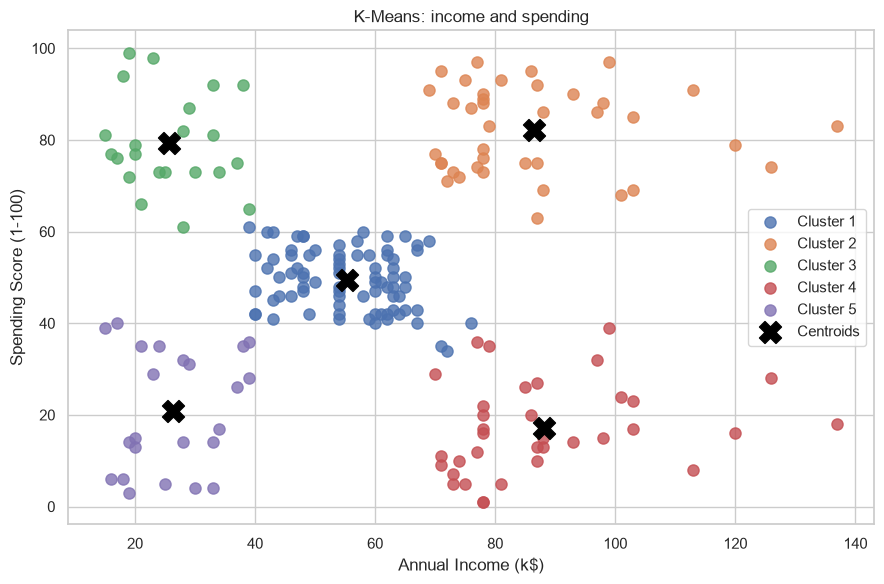

,customers,median_income,median_spending,median_age
cluster,,,,
1,81,54.0,50.0,46.0
2,39,79.0,83.0,32.0
3,22,24.5,77.0,23.5
4,35,85.0,16.0,42.0
5,23,25.0,17.0,46.0


In [10]:
INCOME_CLUSTERS = 5  # Editable exploratory choice; inspect diagnostics above.
if INCOME_CLUSTERS > len(np.unique(X, axis=0)):
    raise ValueError("Income/spending cluster count exceeds distinct cleaned profiles")
kmeans_income = KMeans(n_clusters=INCOME_CLUSTERS, init="k-means++", n_init=N_INIT, random_state=RANDOM_STATE)
y_kmeans = kmeans_income.fit_predict(X)
income_centers = income_scaler.inverse_transform(kmeans_income.cluster_centers_)
plot_clusters(dataset, income_features, y_kmeans, "K-Means: income and spending", income_centers)
income_profiles = dataset.assign(cluster=y_kmeans + 1).groupby("cluster").agg(
    customers=(ID_COLUMN, "size"), median_income=("Annual Income (k$)", "median"),
    median_spending=("Spending Score (1-100)", "median"), median_age=("Age", "median"))
display(income_profiles)


The original interpretation noted high- and low-spending customers within different income bands, including some lower-income high-score customers. Check the current profiles and group sizes before attaching names to segments. A high spending score does not itself measure profitability.

**My notes:** describe the groups and whether five clusters are useful relative to neighboring choices.


## 10. K-Means: age and spending


,k,wcss,silhouette,davies_bouldin
0,1,400.000000,NaN,NaN
1,2,189.387490,0.472127,0.845408
2,3,124.326286,0.439530,0.872905
3,4,89.765217,0.438386,0.824406
4,5,71.244076,0.416010,0.863278
5,6,53.128438,0.456628,0.718405
6,7,45.903799,0.411772,0.822679
7,8,39.185196,0.404830,0.841832
8,9,34.034788,0.436501,0.710401
9,10,28.736284,0.440912,0.712132


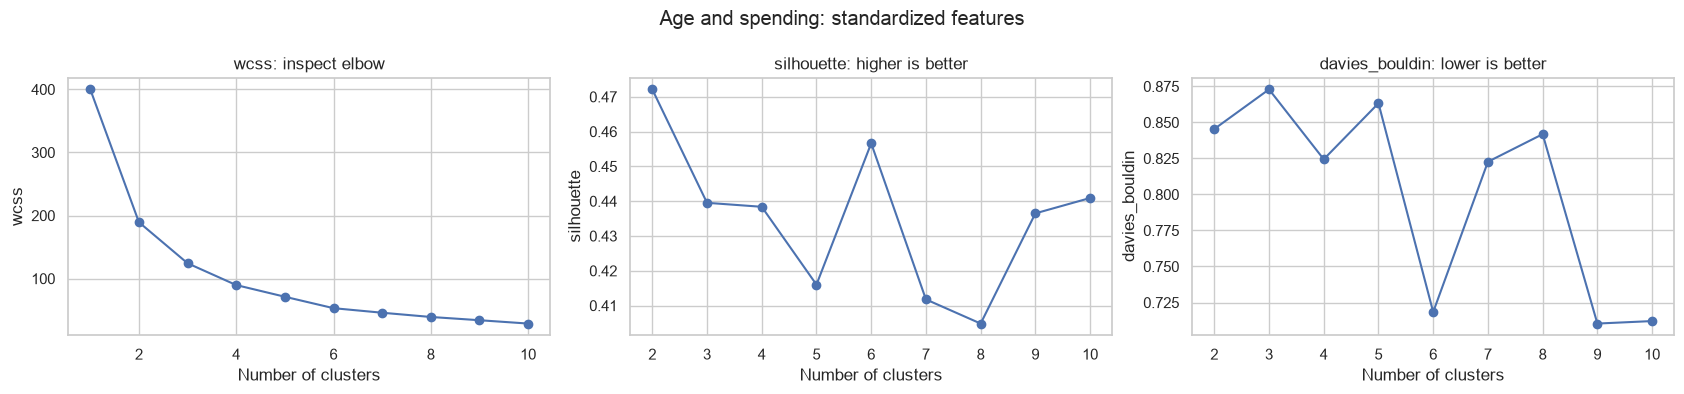

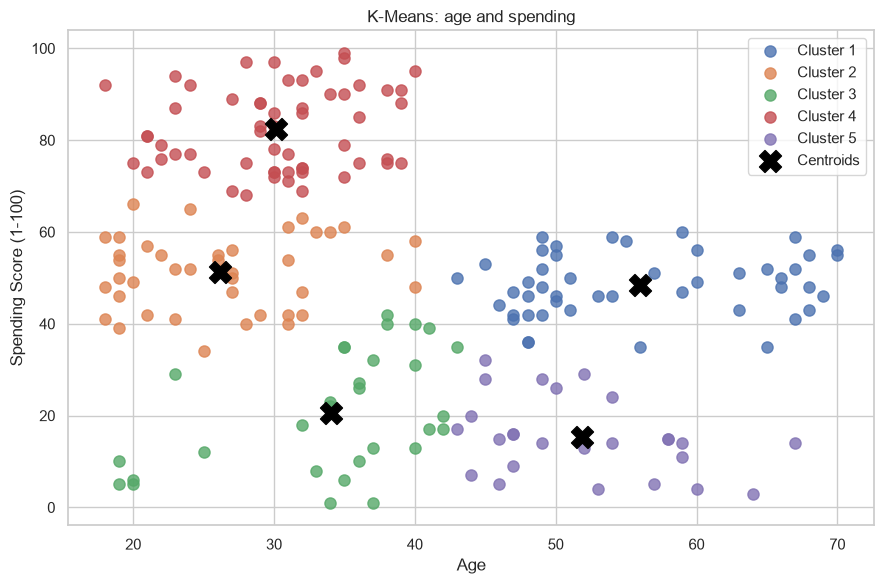

,customers,median_age,median_spending
cluster,,,
1,47,54.0,48.0
2,40,26.0,52.0
3,30,36.0,19.0
4,57,30.0,81.0
5,26,51.0,14.5


In [11]:
age_diagnostics = cluster_diagnostics(Z)
display(age_diagnostics)
plot_diagnostics(age_diagnostics, "Age and spending: standardized features")
AGE_CLUSTERS = 5
if AGE_CLUSTERS > len(np.unique(Z, axis=0)):
    raise ValueError("Age/spending cluster count exceeds distinct cleaned profiles")
kmeans_age = KMeans(n_clusters=AGE_CLUSTERS, init="k-means++", n_init=N_INIT, random_state=RANDOM_STATE)
y_kmeans_age = kmeans_age.fit_predict(Z)
age_centers = age_scaler.inverse_transform(kmeans_age.cluster_centers_)
plot_clusters(dataset, age_features, y_kmeans_age, "K-Means: age and spending", age_centers)
display(dataset.assign(cluster=y_kmeans_age + 1).groupby("cluster").agg(
    customers=(ID_COLUMN, "size"), median_age=("Age", "median"),
    median_spending=("Spending Score (1-100)", "median")))


The original analysis suggested higher scores among younger customers. Review the distributions and segment medians here; do not infer that every younger customer spends more, or that older customers should be excluded from a store strategy.

**My notes:** describe overlap between age groups and how it affects interpretation.


## 11. Ward hierarchical clustering: income and spending
Ward linkage uses Euclidean distances on the same standardized income/spending matrix as K-Means. The dendrogram is truncated for readability. Seven groups retain the original exploratory comparison; inspect whether the added subdivisions are useful.


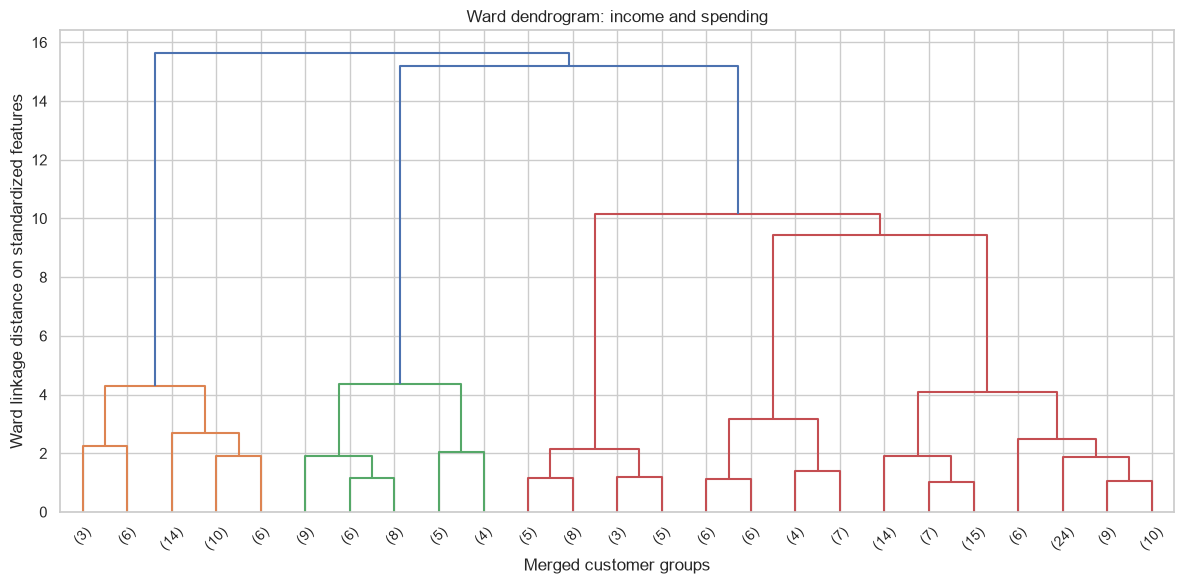

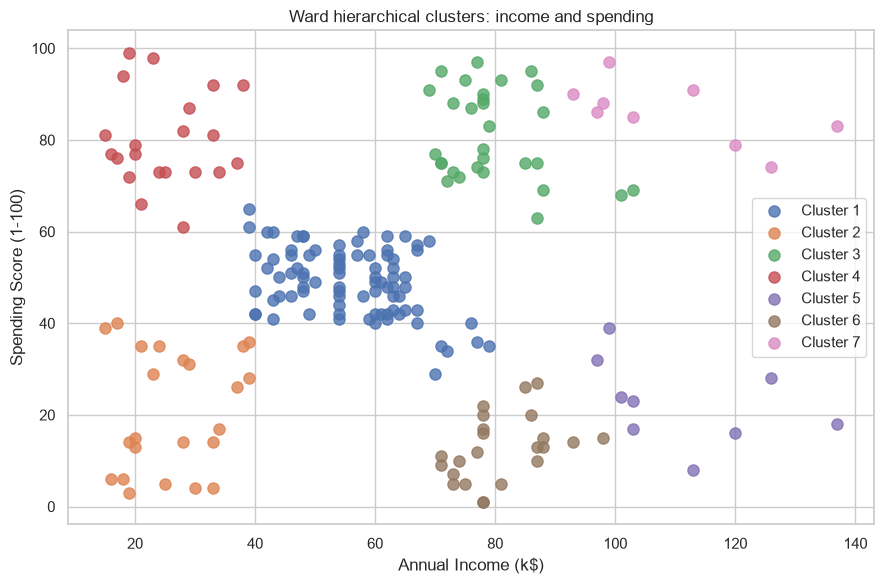

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
shc.dendrogram(shc.linkage(X, method="ward"), truncate_mode="lastp", p=25, ax=ax)
ax.set(title="Ward dendrogram: income and spending", xlabel="Merged customer groups", ylabel="Ward linkage distance on standardized features")
plt.tight_layout()
plt.show()
HIERARCHICAL_CLUSTERS = 7
hc_income = AgglomerativeClustering(n_clusters=HIERARCHICAL_CLUSTERS, metric="euclidean", linkage="ward")
y_hierarchical = hc_income.fit_predict(X)
plot_clusters(dataset, income_features, y_hierarchical, "Ward hierarchical clusters: income and spending")


## 12. All numeric features: age, income and spending
CustomerID and Gender stay outside this feature matrix. All three included features are standardized. Diagnostics operate on the data passed to the function, so no global array is substituted by mistake.


,k,wcss,silhouette,davies_bouldin
0,1,600.000000,NaN,NaN
1,2,389.386189,0.335472,1.260682
2,3,295.212246,0.357793,1.050270
3,4,205.225147,0.403958,0.930796
4,5,168.247580,0.416643,0.874551
5,6,133.868334,0.427428,0.827743
6,7,117.011555,0.417232,0.793467
7,8,103.828578,0.408681,0.889278
8,9,92.349458,0.420074,0.854109
9,10,81.987052,0.397284,0.905614


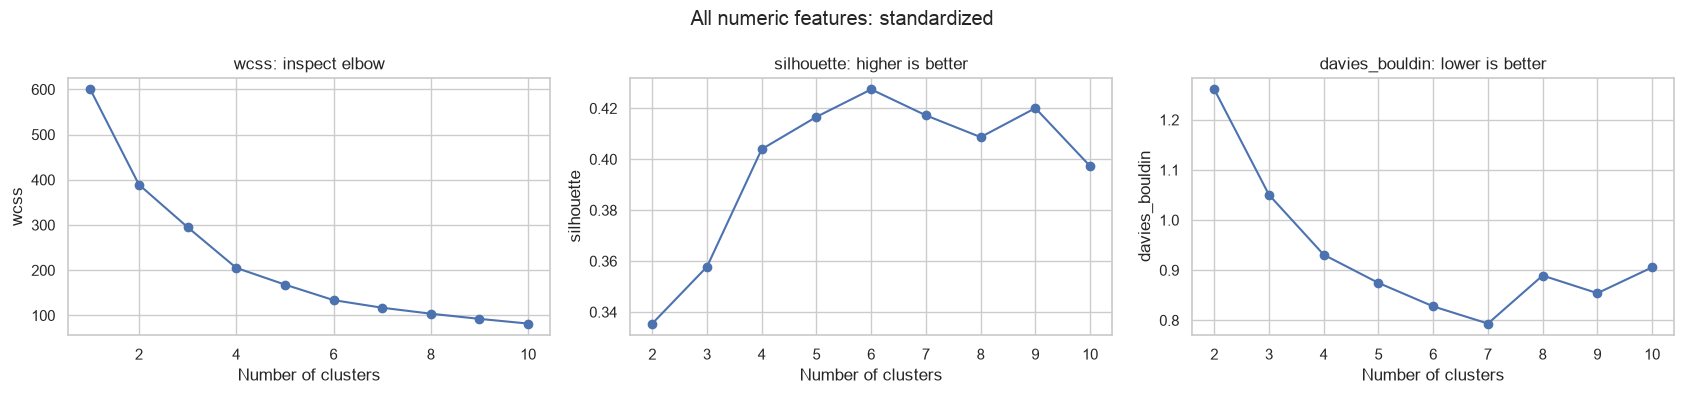

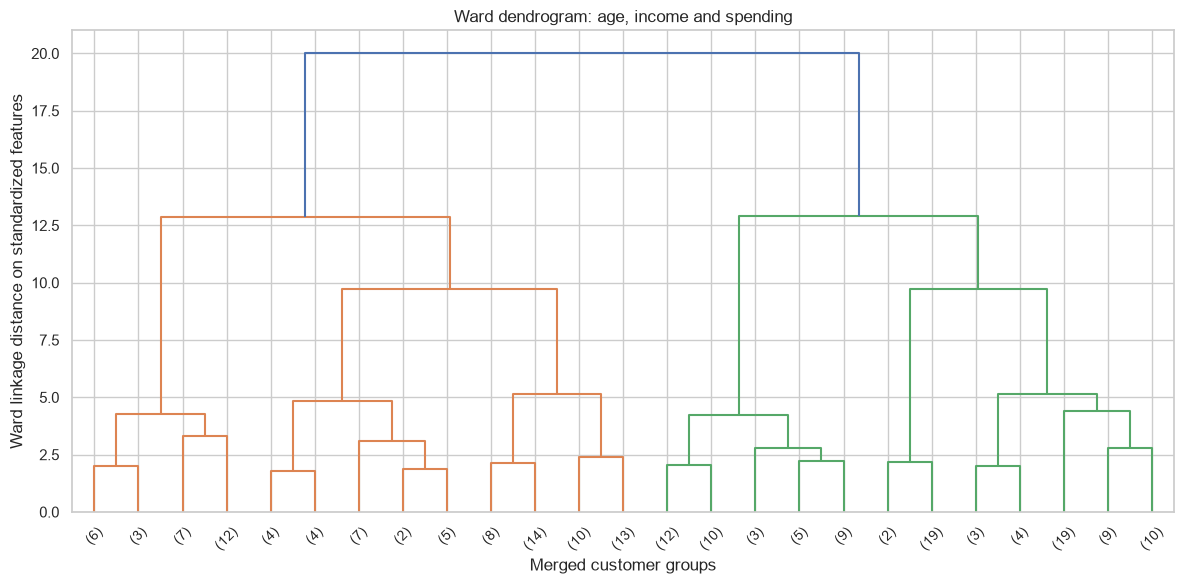

,customers,median_age,median_income,median_spending
cluster,,,,
1,66,24.5,48.0,55.0
2,45,54.0,54.0,48.0
3,39,32.0,79.0,83.0
4,28,43.5,87.0,16.0
5,22,45.5,24.5,16.0


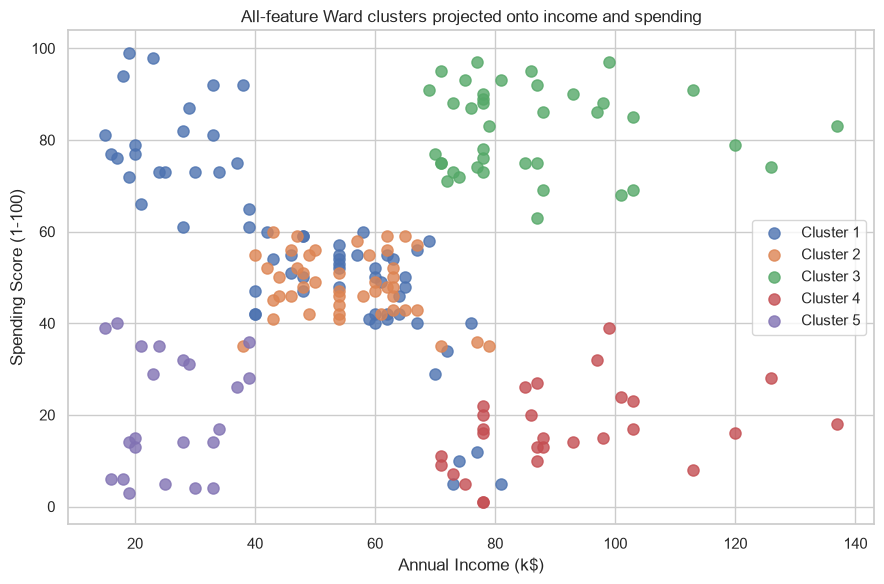

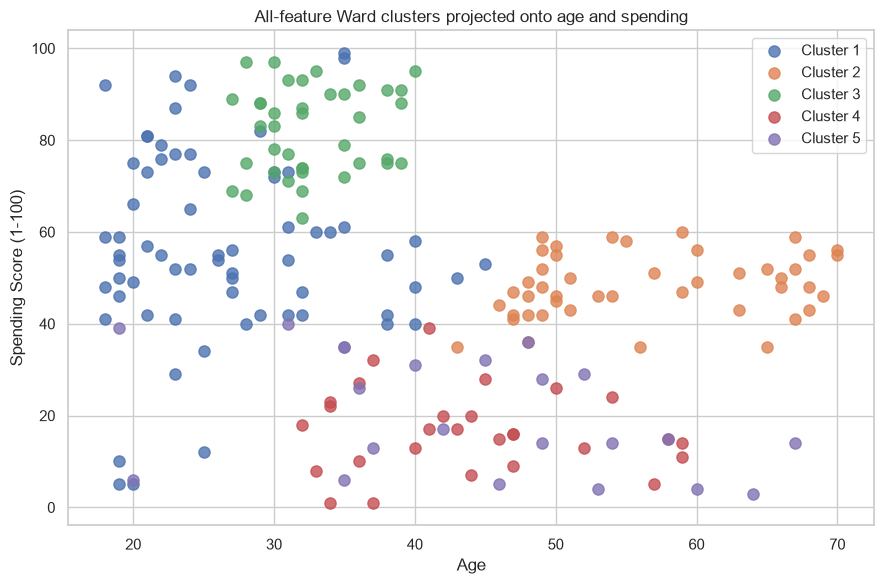

In [13]:
all_diagnostics = cluster_diagnostics(transposed_df)
display(all_diagnostics)
plot_diagnostics(all_diagnostics, "All numeric features: standardized")
fig, ax = plt.subplots(figsize=(12, 6))
shc.dendrogram(shc.linkage(transposed_df, method="ward"), truncate_mode="lastp", p=25, ax=ax)
ax.set(title="Ward dendrogram: age, income and spending", xlabel="Merged customer groups", ylabel="Ward linkage distance on standardized features")
plt.tight_layout()
plt.show()
ALL_FEATURE_CLUSTERS = 5
hc_all = AgglomerativeClustering(n_clusters=ALL_FEATURE_CLUSTERS, metric="euclidean", linkage="ward")
y_all = hc_all.fit_predict(transposed_df)
all_profiles = dataset.assign(cluster=y_all + 1).groupby("cluster").agg(
    customers=(ID_COLUMN, "size"), median_age=("Age", "median"),
    median_income=("Annual Income (k$)", "median"), median_spending=("Spending Score (1-100)", "median"))
display(all_profiles)
plot_clusters(dataset, income_features, y_all, "All-feature Ward clusters projected onto income and spending")
plot_clusters(dataset, age_features, y_all, "All-feature Ward clusters projected onto age and spending")


## 13. Compare and interpret the segmentations
Silhouette and Davies–Bouldin provide internal checks. Compare algorithms using the same feature view, and examine segment sizes, original-unit profiles and sensitivity to cluster count. Cluster numbers are arbitrary and do not match across separate fits.


In [14]:
comparisons = []
for name, features, matrix, labels in [
    ("K-Means", "Income + spending", X, y_kmeans),
    ("Ward", "Income + spending", X, y_hierarchical),
    ("K-Means", "Age + spending", Z, y_kmeans_age),
    ("Ward", "Age + income + spending", transposed_df, y_all),
]:
    comparisons.append({"algorithm": name, "features": features,
                        "clusters": len(np.unique(labels)), "customers": len(labels),
                        "smallest_cluster": int(pd.Series(labels).value_counts().min()),
                        "silhouette": silhouette_score(matrix, labels),
                        "davies_bouldin": davies_bouldin_score(matrix, labels)})
clustering_comparison = pd.DataFrame(comparisons)
display(clustering_comparison)
segmented_customers = dataset.assign(
    income_spending_cluster=y_kmeans + 1,
    age_spending_cluster=y_kmeans_age + 1,
    hierarchical_income_spending_cluster=y_hierarchical + 1,
    hierarchical_all_features_cluster=y_all + 1,
)
display(segmented_customers.head(10))


,algorithm,features,clusters,customers,smallest_cluster,silhouette,davies_bouldin
0,K-Means,Income + spending,5,200,22,0.554657,0.572236
1,Ward,Income + spending,7,200,9,0.519795,0.713283
2,K-Means,Age + spending,5,200,26,0.416010,0.863278
3,Ward,Age + income + spending,5,200,22,0.390028,0.916289


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),income_spending_cluster,age_spending_cluster,hierarchical_income_spending_cluster,hierarchical_all_features_cluster
0,1,Male,19.0,15.0,39.0,5,2,2,5
1,2,Male,21.0,15.0,81.0,3,4,4,1
2,3,Female,20.0,16.0,6.0,5,3,2,5
3,4,Female,23.0,16.0,77.0,3,4,4,1
4,5,Female,31.0,17.0,40.0,5,2,2,5
5,6,Female,22.0,17.0,76.0,3,4,4,1
6,7,Female,35.0,18.0,6.0,5,3,2,5
7,8,Female,23.0,18.0,94.0,3,4,4,1
8,9,Male,64.0,19.0,3.0,5,5,2,5
9,10,Female,30.0,19.0,72.0,3,4,4,1


**My final observations:** summarize useful customer profiles, which feature view best fits the question, how preprocessing affects geometry, and which assumptions need checking on a larger or later sample. This notebook explores the observed customers; it does not establish causal marketing effects or a universal best segmentation.
